# 06 · Analysis E: error analysis
Where do the models make large errors, and do they fail in the same places?
Set `SPLIT = "val"` to analyse the validation year now. Switch to `"test"` only **after** notebook 05 has scored and
frozen 2019, and do not change any model, feature or setting because of what you see there (the test year is scored once).
Everything here only **reads** saved predictions, so nothing is refitted.

In [1]:
import sys, os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
from src import evaluate as ev, metrics as M, models as mo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "axes.titleweight": "bold"})
def savefig(fig, name):
    fig.tight_layout(); fig.savefig(ev.FIGS / f"{name}.png", dpi=150); plt.show()

SPLIT = "val"                      # "val" now; "test" only after Gate G2
MODELS = [n for n in mo.MODELS if all(ev.pred_path(SPLIT, n, h).exists() for h in ev.HORIZONS)]
print("SPLIT:", SPLIT, "| models with saved predictions at both horizons:", MODELS)

SPLIT: val | models with saved predictions at both horizons: ['ridge', 'pca_ridge', 'dt', 'rf', 'ada', 'gb', 'xgb', 'lgbm', 'cat']


## 0. Load: one table per horizon, one prediction column per model
Columns added: `err` = prediction minus actual (vehicles per 15 min), `abs_err`, and segment labels.
Peak = weekday 06:00-09:59 or 15:00-18:59 (by target time). "Sudden change" = how far the target moved away from the
latest reading, in units of the sensor's usual flow (quartiles).

In [2]:
KEEP = ["split", "time", "target_time", "ID2", "corridor", "role", "sc", "y", "y_raw", "flow_t", "precip_mm", "is_holiday", "is_weekend"]
D = {}
for h in ev.HORIZONS:
    tab = ev.load_table(h, columns=KEEP)
    rows0 = None
    for n in MODELS:
        p = pd.read_parquet(ev.pred_path(SPLIT, n, h))
        if rows0 is None:
            rows0 = p["row"].to_numpy(); d = tab.loc[rows0].copy()
        assert np.array_equal(rows0, p["row"].to_numpy()), f"{n} h={h}: different rows than the first model"
        d[f"pred_{n}"] = p["pred"].to_numpy("float64")
    t = d["target_time"]
    hr = t.dt.hour
    d["hour"] = hr
    d["weekend"] = np.where(d["is_holiday"] > 0, "holiday", np.where(d["is_weekend"] > 0, "weekend", "weekday"))
    d["peak"] = np.where((d["weekend"] == "weekday") & (hr.between(6, 9) | hr.between(15, 18)), "peak", "off-peak")
    d["rain"] = np.where(d["precip_mm"] > 0.1, "rain", "dry")
    d["change"] = pd.qcut((d["y"] - d["flow_t"]).abs().rank(method="first"), 4, labels=["Q1 steady", "Q2", "Q3", "Q4 sudden"])
    d["level"] = pd.qcut(d["y"].rank(method="first"), 3, labels=["low flow", "mid flow", "high flow"])
    for n in MODELS:
        d[f"err_{n}"] = d[f"pred_{n}"] - d["y_raw"]
    D[h] = d
    print(f"{h}-minute horizon: {len(d):,} rows, {d['ID2'].nunique()} sensors")

15-minute horizon: 350,587 rows, 80 sensors
60-minute horizon: 350,572 rows, 80 sensors


## 1. Error by segment (WAPE %, lower is better)
WAPE = total absolute error / total actual flow in the segment, so busy and quiet segments are comparable.

In [3]:
def wape_seg(d, col):
    rows = {}
    for key, g in d.groupby(col, observed=True):
        rows[key] = {mo.LABEL[n]: M.wape(g["y_raw"], g[f"pred_{n}"]) * 100 for n in MODELS}
    return pd.DataFrame(rows).T
SEGS = ["peak", "weekend", "rain", "change", "level", "role"]
tables = {}
for h in ev.HORIZONS:
    for s in SEGS:
        t = wape_seg(D[h], s); t.index.name = s
        tables[(h, s)] = t
        t.round(2).to_csv(ev.RESULTS / f"error_{SPLIT}_h{h}_{s}.csv")
    print(f"--- {h}-minute horizon ---")
    for s in SEGS:
        print(tables[(h, s)].round(2).to_string(), "\n")

--- 15-minute horizon ---
          Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
peak                                                                                                                
off-peak   6.66         6.66           6.03           5.66      5.91               5.94     5.52      5.51      5.58
peak       5.99         5.99           5.56           5.28      5.47               5.43     5.16      5.13      5.18 

         Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
weekend                                                                                                            
holiday   9.53         9.53           6.86           6.33      6.66               6.82     6.12      6.11      6.21
weekday   6.42         6.42           5.87           5.55      5.76               5.77     5.42      5.41      5.47
weekend   6.15         6.15           5.

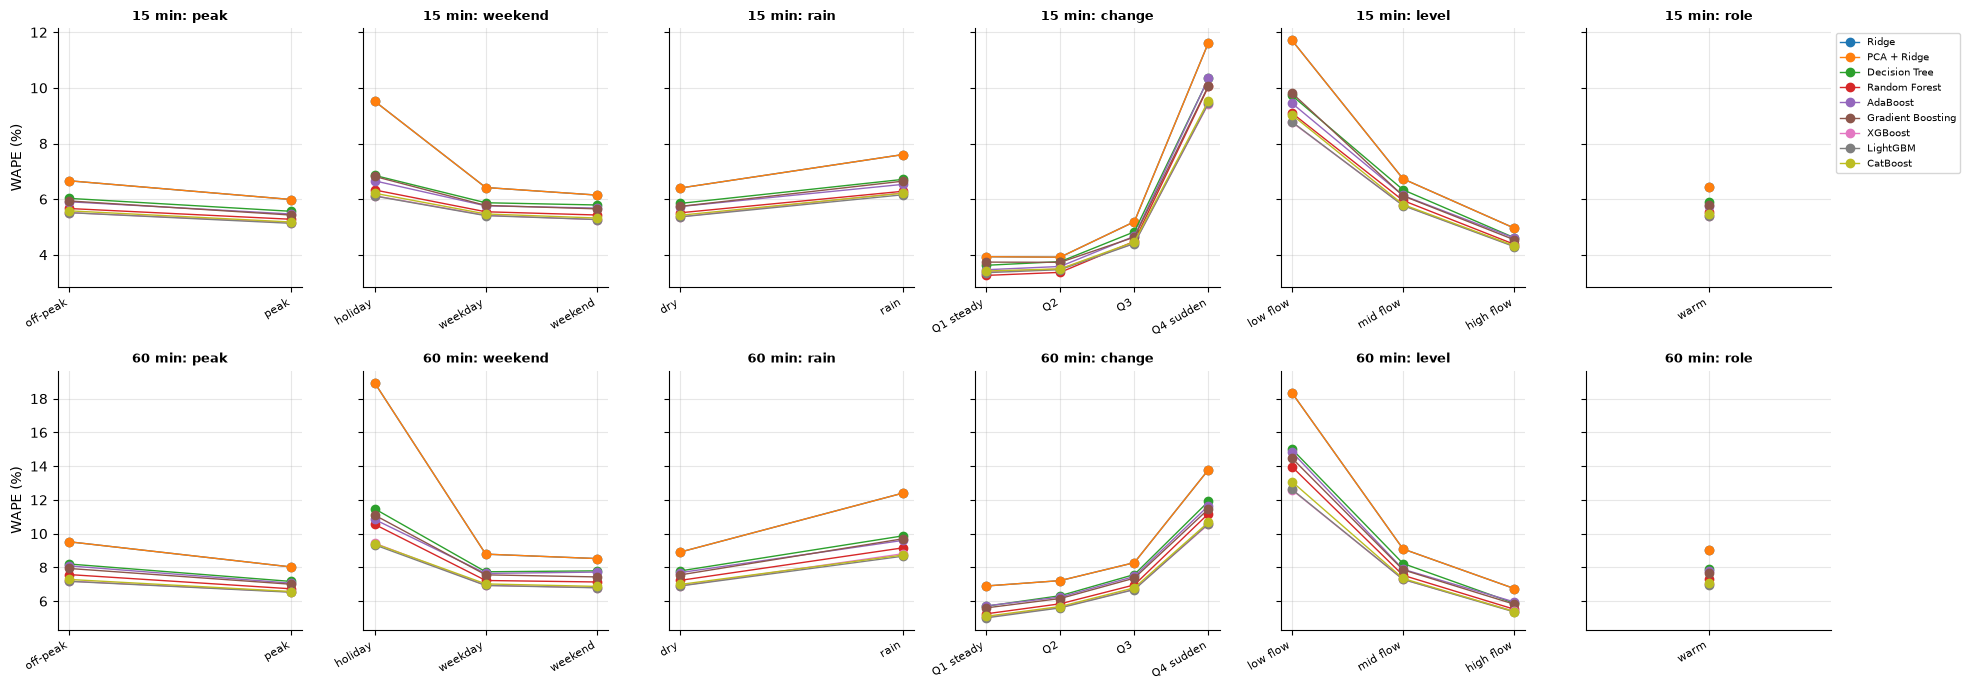

In [4]:
fig, axes = plt.subplots(2, len(SEGS), figsize=(3.3 * len(SEGS), 7), sharey="row")
for r, h in enumerate(ev.HORIZONS):
    for c, s in enumerate(SEGS):
        t = tables[(h, s)]
        for n in t.columns:
            axes[r, c].plot(range(len(t)), t[n], "o-", label=n, lw=1)
        axes[r, c].set_xticks(range(len(t))); axes[r, c].set_xticklabels([str(i) for i in t.index], rotation=30, ha="right", fontsize=8)
        axes[r, c].set_title(f"{h} min: {s}", fontsize=9)
axes[0, 0].set_ylabel("WAPE (%)"); axes[1, 0].set_ylabel("WAPE (%)")
axes[0, -1].legend(fontsize=7, ncol=1, loc="upper left", bbox_to_anchor=(1, 1))
savefig(fig, f"err_segments_{SPLIT}")

## 2. Error by hour of day, weekday vs weekend

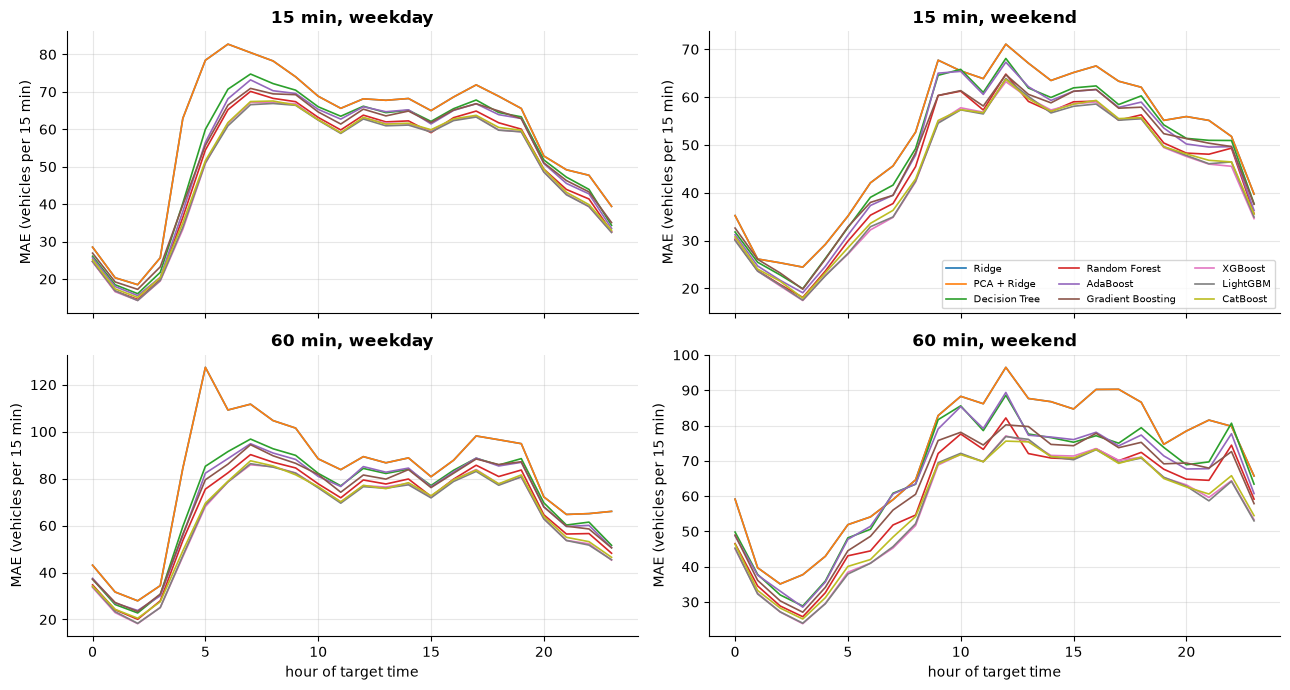

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for r, h in enumerate(ev.HORIZONS):
    for c, wk in enumerate(["weekday", "weekend"]):
        d = D[h][D[h]["weekend"] == wk]
        for n in MODELS:
            axes[r, c].plot(d.groupby("hour")[f"err_{n}"].apply(lambda e: e.abs().mean()), label=mo.LABEL[n], lw=1.2)
        axes[r, c].set_title(f"{h} min, {wk}"); axes[r, c].set_ylabel("MAE (vehicles per 15 min)")
axes[1, 0].set_xlabel("hour of target time"); axes[1, 1].set_xlabel("hour of target time")
axes[0, 1].legend(fontsize=7, ncol=3)
savefig(fig, f"err_by_hour_{SPLIT}")

## 3. Per sensor: is the average hiding a few bad sensors, and do models agree on which?

--- 15 min: ten worst sensors for LightGBM (WAPE %) ---
      Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost    corridor  role
ID2                                                                                                                               
2813   17.0         17.0           16.1           15.8      16.2               15.9     15.9      15.8      15.8   C3_I880-S  warm
2812   17.0         17.0           15.2           14.7      15.2               15.0     14.8      14.5      14.6   C3_I880-S  warm
1422   11.2         11.2           10.8           10.4      10.7               10.5     10.2      10.2      10.2  C2_US101-N  warm
2192   10.8         10.8           10.3           10.0      10.1               10.1      9.9       9.9       9.9   C1_I580-E  warm
721    10.6         10.6           10.3            9.8      10.1               10.0      9.6       9.6       9.6   C4_SR24-W  warm
2191   10.2         10.2   

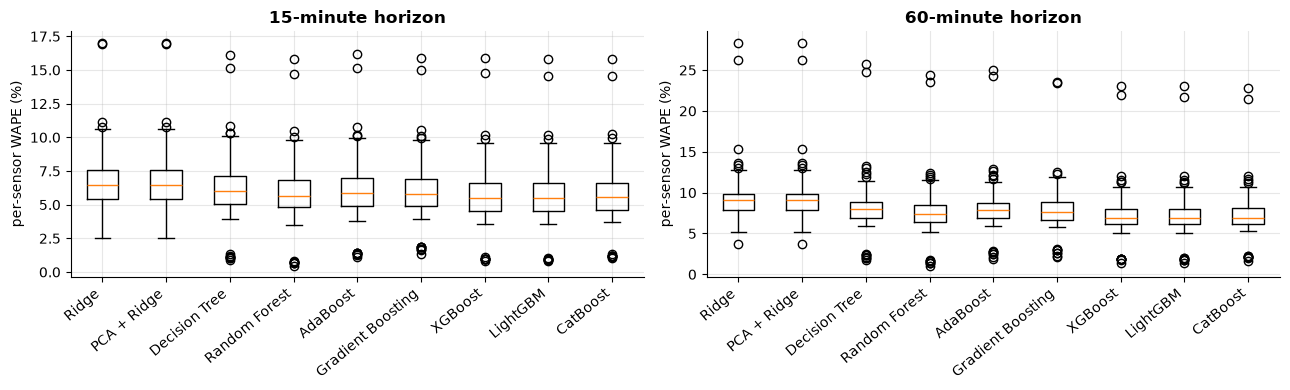

In [6]:
S = {}
for h in ev.HORIZONS:
    g = D[h].groupby("ID2")
    S[h] = pd.DataFrame({mo.LABEL[n]: g.apply(lambda x: M.wape(x["y_raw"], x[f"pred_{n}"]) * 100) for n in MODELS})
    S[h]["corridor"] = g["corridor"].first(); S[h]["role"] = g["role"].first()
    S[h].round(2).to_csv(ev.RESULTS / f"error_{SPLIT}_h{h}_per_sensor.csv")
    best = min(MODELS, key=lambda n: M.mae(D[h]["y_raw"], D[h][f"pred_{n}"]))
    print(f"--- {h} min: ten worst sensors for {mo.LABEL[best]} (WAPE %) ---")
    print(S[h].sort_values(mo.LABEL[best], ascending=False).head(10).round(1).to_string())
    print("rank correlation of per-sensor error between models (Spearman):")
    print(S[h][[mo.LABEL[n] for n in MODELS]].corr(method="spearman").round(2).to_string(), "\n")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, h in zip(axes, ev.HORIZONS):
    ax.boxplot([S[h][mo.LABEL[n]].dropna() for n in MODELS], showfliers=True)
    ax.set_xticks(range(1, len(MODELS) + 1)); ax.set_xticklabels([mo.LABEL[n] for n in MODELS], rotation=40, ha="right")
    ax.set_ylabel("per-sensor WAPE (%)"); ax.set_title(f"{h}-minute horizon")
savefig(fig, f"err_per_sensor_{SPLIT}")

## 4. Do the models fail on the same observations?
Correlation of absolute errors between models, and the overlap of each model's worst 1 % of predictions.
High overlap means the hard cases are hard because of the data (incidents, faults), not because of one model's choices.

In [7]:
for h in ev.HORIZONS:
    A = pd.DataFrame({mo.LABEL[n]: D[h][f"err_{n}"].abs() for n in MODELS})
    print(f"--- {h} min: correlation of absolute errors ---")
    print(A.corr().round(2).to_string())
    top = {c: set(A[c].nlargest(int(len(A) * 0.01)).index) for c in A.columns}
    ref = mo.LABEL[min(MODELS, key=lambda n: M.mae(D[h]["y_raw"], D[h][f"pred_{n}"]))]
    print(f"share of {ref}'s worst 1% that is also in each model's worst 1%:")
    print({c: round(len(top[ref] & top[c]) / len(top[ref]), 2) for c in A.columns}, "\n")

--- 15 min: correlation of absolute errors ---
                   Ridge  PCA + Ridge  Decision Tree  Random Forest  AdaBoost  Gradient Boosting  XGBoost  LightGBM  CatBoost
Ridge               1.00         1.00           0.86           0.90      0.89               0.90     0.85      0.85      0.86
PCA + Ridge         1.00         1.00           0.86           0.90      0.89               0.90     0.85      0.85      0.86
Decision Tree       0.86         0.86           1.00           0.94      0.94               0.92     0.90      0.91      0.90
Random Forest       0.90         0.90           0.94           1.00      0.98               0.97     0.94      0.95      0.95
AdaBoost            0.89         0.89           0.94           0.98      1.00               0.96     0.92      0.93      0.93
Gradient Boosting   0.90         0.90           0.92           0.97      0.96               1.00     0.93      0.94      0.95
XGBoost             0.85         0.85           0.90           0.94    

## 5. The worst cases of the best model, and what they have in common

In [8]:
for h in ev.HORIZONS:
    d = D[h]; best = min(MODELS, key=lambda n: M.mae(d["y_raw"], d[f"pred_{n}"]))
    d = d.assign(abs_err=d[f"err_{best}"].abs(), pred=d[f"pred_{best}"], last_reading=d["flow_t"] * d["sc"])
    worst = d.nlargest(int(len(d) * 0.01), "abs_err")
    print(f"--- {h} min, {mo.LABEL[best]}: worst 1% = {len(worst):,} rows, they carry {worst['abs_err'].sum() / d['abs_err'].sum() * 100:.1f}% of all absolute error ---")
    cmp = pd.DataFrame({"share of worst 1% (%)": [worst[c].value_counts(normalize=True).get(v, 0) * 100 for c, v in
                        [("peak", "peak"), ("weekend", "weekend"), ("weekend", "holiday"), ("rain", "rain"), ("change", "Q4 sudden")]],
                        "share of all rows (%)": [d[c].value_counts(normalize=True).get(v, 0) * 100 for c, v in
                        [("peak", "peak"), ("weekend", "weekend"), ("weekend", "holiday"), ("rain", "rain"), ("change", "Q4 sudden")]]},
                       index=["peak hours", "weekends", "holidays", "rain", "sudden change (top quartile)"])
    print(cmp.round(1).to_string(), "\n")
    print(worst.sort_values("abs_err", ascending=False).head(15)[["target_time", "ID2", "corridor", "y_raw", "pred", "last_reading", "precip_mm", "weekend"]].round(0).to_string(), "\n")

--- 15 min, LightGBM: worst 1% = 3,505 rows, they carry 8.4% of all absolute error ---
                              share of worst 1% (%)  share of all rows (%)
peak hours                                     37.8                   22.8
weekends                                       21.3                   27.9
holidays                                        3.0                    3.8
rain                                            5.2                    4.1
sudden change (top quartile)                   95.9                   25.0 

                target_time   ID2    corridor   y_raw    pred  last_reading  precip_mm  weekend
1142740 2018-09-29 12:15:00  2176   C1_I580-E   130.0  2425.0        2614.0        0.0  weekend
871035  2018-12-20 12:15:00  1428  C2_US101-N     0.0  2091.0        2061.0        0.0  weekday
973080  2018-12-20 12:15:00  1432  C2_US101-N     0.0  1884.0        1967.0        0.0  weekday
1195846 2018-12-20 12:15:00  2178   C1_I580-E     0.0  1862.0        1895.0  

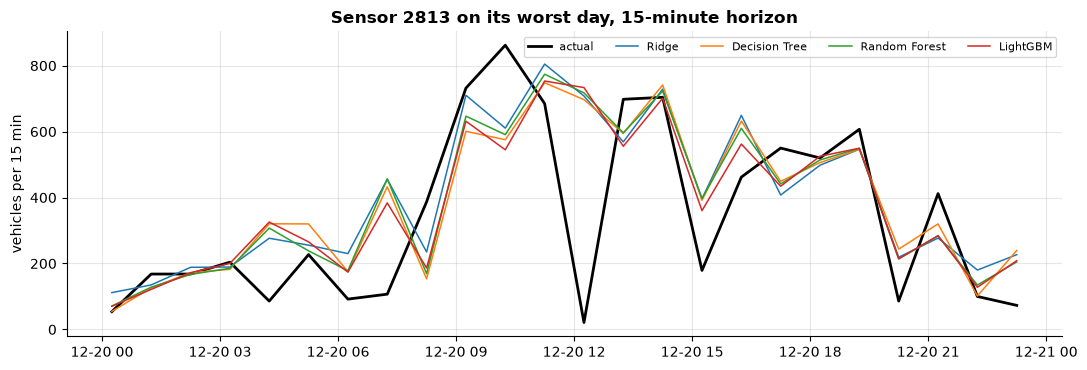

In [9]:
h = 15; d = D[h]; best = min(MODELS, key=lambda n: M.mae(d["y_raw"], d[f"pred_{n}"]))
worst_sensor = S[h][mo.LABEL[best]].idxmax()
day = d[(d["ID2"] == worst_sensor)]
day = day[day["target_time"].dt.normalize() == day.loc[day[f"err_{best}"].abs().idxmax(), "target_time"].normalize()].sort_values("target_time")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(day["target_time"], day["y_raw"], "k-", lw=2, label="actual")
for n in MODELS:
    if n in ("lgbm", "rf", "dt", "ridge"):
        ax.plot(day["target_time"], day[f"pred_{n}"], lw=1.1, label=mo.LABEL[n])
ax.set_title(f"Sensor {worst_sensor} on its worst day, 15-minute horizon"); ax.set_ylabel("vehicles per 15 min"); ax.legend(ncol=5, fontsize=8)
savefig(fig, f"err_worst_day_{SPLIT}")

## 6. Interpretation (write this yourself after reading the tables above)
Fill in three or four sentences for each question, using numbers from the tables:
1. **Peak vs off-peak, weekday vs weekend, rain vs dry:** which segment has the highest WAPE, and by how much?
2. **Sudden changes:** how much worse is the top change quartile than the steadiest quartile, and which models cope best?
3. **Sensors:** are a few sensors responsible for much of the error? Are they the same for every model?
4. **Model differences:** do the models fail on the same rows (section 4)? What does that say about the data vs the models?
5. **Limitations:** what error is not explainable from these features (incidents, sensor faults)?